In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.datasets import fetch_openml
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

import warnings
warnings.filterwarnings("ignore")

seed = 1234
rng = np.random.default_rng(seed)
np.random.seed(seed)

# Data Loading and Partitioning
- **Training set (`X_tr`, `y_tr`):** 18,750 reviews (75% of 25,000 = 37.5% of 50k)
- **Validation set (`X_val`, `y_val`):** 6,250 reviews (25% of 25,000 = 12.5% of 50k)
- **Test set (`X_te`, `y_te`):** 25,000 reviews (50% of 50k, untouched until final evaluation)

In [ ]:
from datasets import load_dataset


def load_imdb_raw():
    """Load IMDB raw review texts and binary labels using Hugging Face datasets."""
    ds = load_dataset("stanfordnlp/imdb")

    tr_txt = [str(x) for x in ds["train"]["text"]]
    tr_y = np.asarray(ds["train"]["label"], dtype=np.int64)

    te_txt = [str(x) for x in ds["test"]["text"]]
    te_y = np.asarray(ds["test"]["label"], dtype=np.int64)

    return tr_txt, tr_y, te_txt, te_y


raw_tr_texts, raw_tr_y, raw_te_texts, raw_te_y = load_imdb_raw()

tr_texts, val_texts, y_tr, y_val = train_test_split(
    raw_tr_texts,
    raw_tr_y,
    test_size=0.25,
    random_state=seed,
    stratify=raw_tr_y,
)
te_texts = raw_te_texts
y_te = raw_te_y

vocab_size = 10000
vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    ngram_range=(1, 2),
    sublinear_tf=True,
    dtype=np.float32,
)
X_tr = vectorizer.fit_transform(tr_texts)
X_val = vectorizer.transform(val_texts)
X_te = vectorizer.transform(te_texts)

print(f"Train shape: {X_tr.shape}, pos rate: {y_tr.mean():.3f}")
print(f"Val   shape: {X_val.shape}, pos rate: {y_val.mean():.3f}")
print(f"Test  shape: {X_te.shape}, pos rate: {y_te.mean():.3f}")

Train shape: (18750, 10000), pos rate: 0.500
Val   shape: (6250, 10000), pos rate: 0.500
Test  shape: (25000, 10000), pos rate: 0.500


# Exploratory Data Analysis

Train review word count — mean: 233.5, median: 174.0, std: 174.1, max: 2470
Test  review word count — mean: 228.5, median: 172.0, std: 168.9, max: 2278


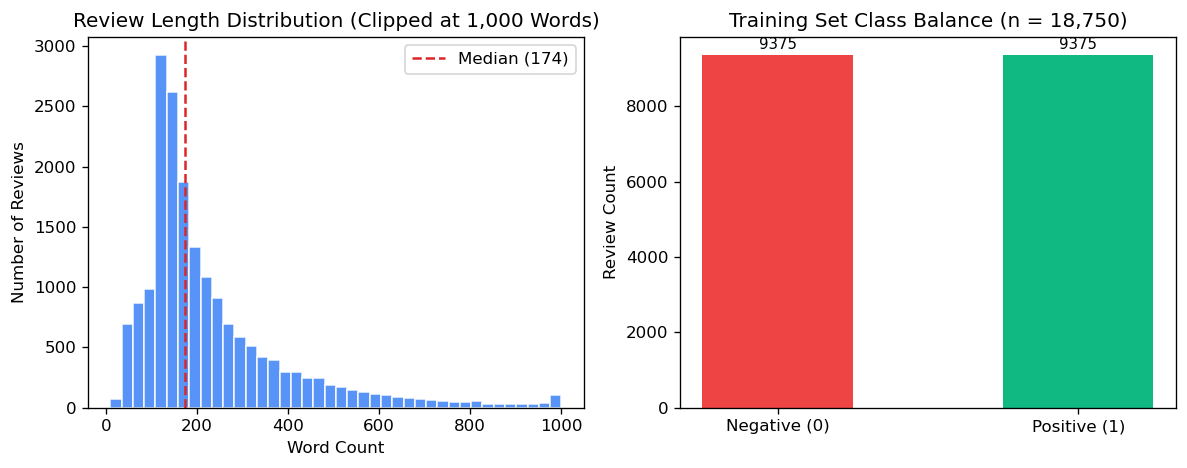

In [3]:
tr_lengths = np.array([len(t.split()) for t in tr_texts])
te_lengths = np.array([len(t.split()) for t in te_texts])

print("Train review word count — mean: %.1f, median: %.1f, std: %.1f, max: %d" % (
    tr_lengths.mean(), np.median(tr_lengths), tr_lengths.std(), tr_lengths.max()
))
print("Test  review word count — mean: %.1f, median: %.1f, std: %.1f, max: %d" % (
    te_lengths.mean(), np.median(te_lengths), te_lengths.std(), te_lengths.max()
))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=120)

clipped_tr = np.clip(tr_lengths, 0, 1000)
axes[0].hist(clipped_tr, bins=40, color="#3b82f6", alpha=0.85, edgecolor="white")
axes[0].axvline(np.median(tr_lengths), color="#dc2626", linestyle="--", label=f"Median ({np.median(tr_lengths):.0f})")
axes[0].set_title("Review Length Distribution (Clipped at 1,000 Words)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Reviews")
axes[0].legend()

class_counts = [np.sum(y_tr == 0), np.sum(y_tr == 1)]
axes[1].bar(["Negative (0)", "Positive (1)"], class_counts, color=["#ef4444", "#10b981"], width=0.5)
axes[1].set_title("Training Set Class Balance (n = 18,750)")
axes[1].set_ylabel("Review Count")
for idx, val in enumerate(class_counts):
    axes[1].text(idx, val + 150, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("imdb_eda_summary.png", dpi=120)
plt.show()

# Varying Amounts of Training Data

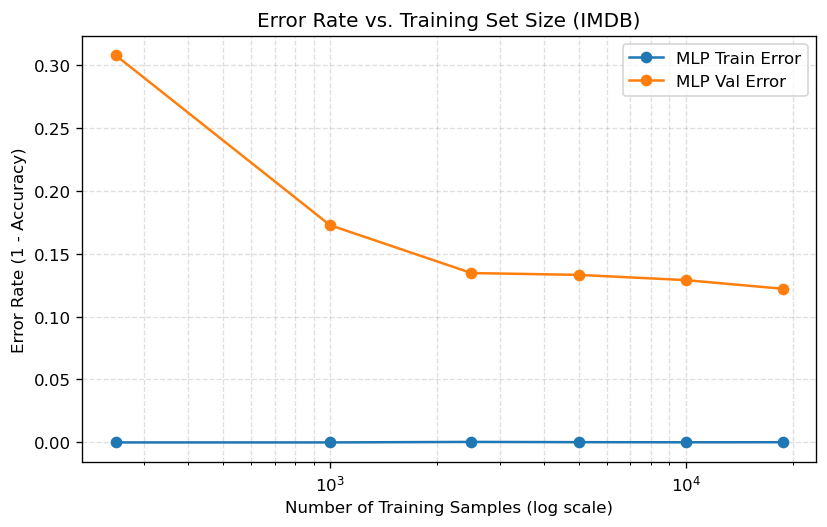

In [4]:
n_tr_values = [250, 1000, 2500, 5000, 10000, len(y_tr)]


def train_models_varying_data(X_tr, y_tr, X_eval, y_eval, n_tr_values, model_factory):
    train_errors = []
    eval_errors = []
    for n in n_tr_values:
        model = model_factory()
        model.fit(X_tr[:n], y_tr[:n])
        train_errors.append(1.0 - accuracy_score(y_tr[:n], model.predict(X_tr[:n])))
        eval_errors.append(1.0 - accuracy_score(y_eval, model.predict(X_eval)))
    return np.asarray(train_errors), np.asarray(eval_errors)


mlp_base_factory = lambda: MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    alpha=1e-4,
    batch_size=256,
    max_iter=20,
    early_stopping=False,
    random_state=seed,
)

mlp_tr_err, mlp_val_err = train_models_varying_data(
    X_tr, y_tr, X_val, y_val, n_tr_values, mlp_base_factory
)

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.plot(n_tr_values, mlp_tr_err, marker="o", label="MLP Train Error")
ax.plot(n_tr_values, mlp_val_err, marker="o", label="MLP Val Error")
ax.set_xscale("log")
ax.set_xlabel("Number of Training Samples (log scale)")
ax.set_ylabel("Error Rate (1 - Accuracy)")
ax.set_title("Error Rate vs. Training Set Size (IMDB)")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("imdb_varying_data.png", dpi=120)
plt.show()

# Learning Loss Rate Curves

lr=0.0005: 25 epochs, final loss=0.0331
lr=0.001: 25 epochs, final loss=0.0185
lr=0.005: 25 epochs, final loss=0.0270
lr=0.01: 25 epochs, final loss=0.0662


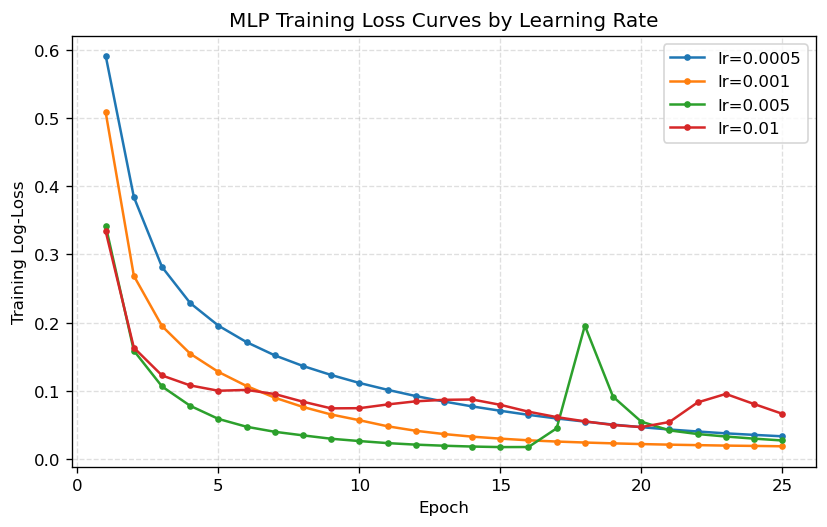

In [5]:
lrs = [0.0005, 0.001, 0.005, 0.01]
lr_loss_curves = {}

for lr in lrs:
    mlp_lc = MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        solver="adam",
        learning_rate_init=lr,
        alpha=1e-3,
        batch_size=256,
        max_iter=25,
        n_iter_no_change=25,
        random_state=seed,
    )
    mlp_lc.fit(X_tr, y_tr)
    lr_loss_curves[lr] = mlp_lc.loss_curve_
    print(f"lr={lr}: {len(mlp_lc.loss_curve_)} epochs, final loss={mlp_lc.loss_curve_[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
for lr, curve in lr_loss_curves.items():
    ax.plot(range(1, len(curve) + 1), curve, marker=".", label=f"lr={lr}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Log-Loss")
ax.set_title("MLP Training Loss Curves by Learning Rate")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("imdb_learning_curves.png", dpi=120)
plt.show()

# Hyperparameter Tuning on Validation Set

In [6]:
architectures = [(64,), (128,), (256,), (128, 64)]
alphas = [1e-4, 1e-3, 1e-2, 1e-1]

tuning_records = []
best_val_acc = -1.0
best_params = None
best_model = None

for arch in architectures:
    for alpha in alphas:
        t0 = time.perf_counter()
        clf = MLPClassifier(
            hidden_layer_sizes=arch,
            activation="relu",
            solver="adam",
            learning_rate_init=1e-3,
            alpha=alpha,
            batch_size=256,
            max_iter=30,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=5,
            random_state=seed,
        )
        clf.fit(X_tr, y_tr)
        elapsed = time.perf_counter() - t0

        tr_acc = accuracy_score(y_tr, clf.predict(X_tr))
        val_acc = accuracy_score(y_val, clf.predict(X_val))

        tuning_records.append({
            "architecture": str(arch),
            "alpha": alpha,
            "train_acc": tr_acc,
            "val_acc": val_acc,
            "val_err": 1.0 - val_acc,
            "train_sec": round(elapsed, 2),
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = {"hidden_layer_sizes": arch, "alpha": alpha}
            best_model = clf

tuning_df = pd.DataFrame(tuning_records).sort_values("val_acc", ascending=False)
print("Best validation hyperparameters:", best_params, f"(val_acc={best_val_acc:.4f})")
display(tuning_df.head(10))

Best validation hyperparameters: {'hidden_layer_sizes': (128, 64), 'alpha': 0.1} (val_acc=0.8922)


,architecture,alpha,train_acc,val_acc,val_err,train_sec
15,"(128, 64)",0.1000,0.965120,0.89216,0.10784,29.48
9,"(256,)",0.0010,0.945760,0.89184,0.10816,60.04
8,"(256,)",0.0001,0.945920,0.89168,0.10832,68.86
10,"(256,)",0.0100,0.945173,0.89168,0.10832,61.10
11,"(256,)",0.1000,0.944747,0.89136,0.10864,72.92
0,"(64,)",0.0001,0.958827,0.89120,0.10880,22.79
1,"(64,)",0.0010,0.958667,0.89104,0.10896,23.24
2,"(64,)",0.0100,0.947467,0.89088,0.10912,17.37
5,"(128,)",0.0010,0.952053,0.89072,0.10928,37.33
7,"(128,)",0.1000,0.969813,0.89056,0.10944,80.34


# Final Test Evaluation and Error Analysis

In [ ]:
y_tr_pred = best_model.predict(X_tr)
y_val_pred = best_model.predict(X_val)
y_te_pred = best_model.predict(X_te)

metrics_summary = pd.DataFrame([
    {
        "Split": "Train",
        "Accuracy": accuracy_score(y_tr, y_tr_pred),
        "Error Rate": 1.0 - accuracy_score(y_tr, y_tr_pred),
        "Precision": precision_score(y_tr, y_tr_pred),
        "Recall": recall_score(y_tr, y_tr_pred),
        "F1": f1_score(y_tr, y_tr_pred),
    },
    {
        "Split": "Validation",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Error Rate": 1.0 - accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred),
    },
    {
        "Split": "Test (Final)",
        "Accuracy": accuracy_score(y_te, y_te_pred),
        "Error Rate": 1.0 - accuracy_score(y_te, y_te_pred),
        "Precision": precision_score(y_te, y_te_pred),
        "Recall": recall_score(y_te, y_te_pred),
        "F1": f1_score(y_te, y_te_pred),
    },
])
display(metrics_summary.round(4))
print("Test Confusion Matrix:\n", confusion_matrix(y_te, y_te_pred))

np.savez("mlp_imdb_test_outputs.npz", y_te=y_te, y_te_pred=y_te_pred)

error_indices = np.where(y_te_pred != y_te)[0]
print(f"\nTotal test errors: {len(error_indices)} / {len(y_te)}")
for idx in error_indices[:5]:
    snippet = te_texts[idx].replace("<br />", " ")[:260]
    print(f"[Idx {idx}] True={y_te[idx]}, Pred={y_te_pred[idx]} | {snippet}...")

,Split,Accuracy,Error Rate,Precision,Recall,F1
0,Train,0.9651,0.0349,0.9680,0.9620,0.9650
1,Validation,0.8922,0.1078,0.8988,0.8838,0.8913
2,Test (Final),0.8876,0.1124,0.8977,0.8749,0.8862


Test Confusion Matrix:
 [[11254  1246]
 [ 1564 10936]]

Total test errors: 2810 / 25000
[Idx 4] True=0, Pred=1 | First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much bett...
[Idx 18] True=0, Pred=1 | Ben, (Rupert Grint), is a deeply unhappy adolescent, the son of his unhappily married parents. His father, (Nicholas Farrell), is a vicar and his mother, (Laura Linney), is ... well, let's just say she's a somewhat hypocritical soldier in Jesus' army. It's onl...
[Idx 22] True=0, Pred=1 | The Forgotten (AKA: Don't Look In The Basement) is a very cheaply made and very old looking horror movie.  The story is very slow and never really reaches anything worth getting excited about.  The patients at the asylum are embarrassingly funny especially Sam...
[Idx 32] True=0, Pred=1 | I'm the type of g